# Data Science Consulting Project - Global Coffee Company

In [150]:
import sys
# print(sys.executable)

import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

In [151]:
# remove scientific notation for display purposes
pd.options.display.float_format = '{:,.0f}'.format

In [152]:
# load csv files into pandas data frames
coffee_exp = pd.read_csv("coffee_ex.csv")
coffee_imp = pd.read_csv("coffee_imp.csv")
coffee_prod = pd.read_csv("coffee_prod.csv")

## 0. Basic Data Cleaning

#### fix index labels to match across datasets

In [153]:
#fix production "Country" labels out of order with sort_values()
coffee_prod = coffee_prod.sort_values(by="Country")

# compare country names
pd.concat([coffee_exp["Country"],coffee_imp["Country"],coffee_prod["Country"].reset_index(drop=True)], axis="columns")

,Country,Country,Country
0,Angola,Austria,Angola
1,Bolivia (Plurinational State of),Belgium,Bolivia (Plurinational State of)
2,Brazil,Belgium/Luxembourg,Brazil
3,Burundi,Bulgaria,Burundi
4,Cameroon,Croatia,Cameroon
5,Central African Republic,Cyprus,Central African Republic
6,Colombia,Czechia,Colombia
7,Congo,Denmark,Congo
8,Costa Rica,Estonia,Costa Rica
9,Côte d'Ivoire,Finland,Cuba


In [154]:
# note: only run once

coffee_exp = coffee_exp.set_index("Country")
coffee_imp = coffee_imp.set_index("Country")
coffee_prod = coffee_prod.set_index("Country") 


In [155]:
# write an index cleaning function
def cleanUpCountryLabels(indx):
    newindx = indx.astype(str).str.strip().str.upper() #check for non-string types, stripe white space, change all to upper-case 
    return newindx

coffee_exp.index = cleanUpCountryLabels(coffee_exp.index)
coffee_imp.index = cleanUpCountryLabels(coffee_imp.index)
coffee_prod.index = cleanUpCountryLabels(coffee_prod.index)

In [156]:
print(coffee_exp.index, coffee_imp.index, coffee_prod.index)

Index(['ANGOLA', 'BOLIVIA (PLURINATIONAL STATE OF)', 'BRAZIL', 'BURUNDI',
       'CAMEROON', 'CENTRAL AFRICAN REPUBLIC', 'COLOMBIA', 'CONGO',
       'COSTA RICA', 'CÔTE D'IVOIRE', 'CUBA', 'DEMOCRATIC REPUBLIC OF CONGO',
       'DOMINICAN REPUBLIC', 'ECUADOR', 'EL SALVADOR', 'EQUATORIAL GUINEA',
       'ETHIOPIA', 'GABON', 'GHANA', 'GUATEMALA', 'GUINEA', 'GUYANA', 'HAITI',
       'HONDURAS', 'INDIA', 'INDONESIA', 'JAMAICA', 'KENYA',
       'LAO PEOPLE'S DEMOCRATIC REPUBLIC', 'LIBERIA', 'MADAGASCAR', 'MALAWI',
       'MEXICO', 'NEPAL', 'NICARAGUA', 'NIGERIA', 'PANAMA', 'PAPUA NEW GUINEA',
       'PARAGUAY', 'PERU', 'PHILIPPINES', 'RWANDA', 'SIERRA LEONE',
       'SRI LANKA', 'TANZANIA', 'THAILAND', 'TIMOR-LESTE', 'TOGO',
       'TRINIDAD & TOBAGO', 'UGANDA', 'VENEZUELA', 'VIET NAM', 'YEMEN',
       'ZAMBIA', 'ZIMBABWE'],
      dtype='str', name='Country') Index(['AUSTRIA', 'BELGIUM', 'BELGIUM/LUXEMBOURG', 'BULGARIA', 'CROATIA',
       'CYPRUS', 'CZECHIA', 'DENMARK', 'ESTONIA', 'FINLAND',

#### fix column labels to be numbers and uniform year values

In [157]:
#checks
coffee_exp.columns.is_unique
coffee_exp.columns.dtype
coffee_exp.columns
#cleaning
cols = coffee_exp.columns.astype(str).str.strip()
years = pd.to_numeric(cols[:-1])
coffee_exp.columns = list(years) + [cols[-1]] #make years a list so that it joins the columns list
coffee_exp.columns

Index([          1990,           1991,           1992,           1993,
                 1994,           1995,           1996,           1997,
                 1998,           1999,           2000,           2001,
                 2002,           2003,           2004,           2005,
                 2006,           2007,           2008,           2009,
                 2010,           2011,           2012,           2013,
                 2014,           2015,           2016,           2017,
                 2018,           2019, 'Total_export'],
      dtype='object')

In [158]:
#checks
coffee_imp.columns.is_unique
coffee_imp.columns.dtype
coffee_imp.columns
#cleaning
cols = coffee_imp.columns.str.strip()
years = pd.to_numeric(cols[:-1])
coffee_imp.columns = list(years) + [cols[-1]]
coffee_imp.columns

Index([          1990,           1991,           1992,           1993,
                 1994,           1995,           1996,           1997,
                 1998,           1999,           2000,           2001,
                 2002,           2003,           2004,           2005,
                 2006,           2007,           2008,           2009,
                 2010,           2011,           2012,           2013,
                 2014,           2015,           2016,           2017,
                 2018,           2019, 'Total_import'],
      dtype='object')

In [159]:
#checks
coffee_prod.columns.is_unique
coffee_prod.columns.inferred_type
coffee_prod.columns
#cleaning
cols = coffee_prod.columns.astype(str).str.strip() #only select year columns for range utility
years = pd.to_numeric(cols[1:-1].str[:4]) #use .str to remove mismatched string endings: '1990/91' -> 1990
coffee_prod.columns = [cols[0]] + list(years) + [cols[-1]]
coffee_prod.columns

Index([     'Coffee type',               1990,               1991,
                     1992,               1993,               1994,
                     1995,               1996,               1997,
                     1998,               1999,               2000,
                     2001,               2002,               2003,
                     2004,               2005,               2006,
                     2007,               2008,               2009,
                     2010,               2011,               2012,
                     2013,               2014,               2015,
                     2016,               2017,               2018,
                     2019, 'Total_production'],
      dtype='object')

In [160]:
#conversion demonstration
print("coffee_exp.columns: ", coffee_exp.columns.tolist()[:3], coffee_exp.columns.dtype)
print("coffee_imp.columns: ", coffee_imp.columns.tolist()[:3], coffee_imp.columns.dtype)
print("coffee_prod.columns: ", coffee_prod.columns.tolist()[:3], coffee_prod.columns.dtype)

coffee_exp.columns:  [1990, 1991, 1992] object
coffee_imp.columns:  [1990, 1991, 1992] object
coffee_prod.columns:  ['Coffee type', 1990, 1991] object


#### pd.to_numeric

In [161]:
coffee_exp = coffee_exp.apply(pd.to_numeric, errors="coerce")
coffee_imp = coffee_imp.apply(pd.to_numeric, errors="coerce")

num_cols = coffee_prod.columns[1:] #everything except "Coffee type" 
coffee_prod[num_cols] = coffee_prod[num_cols].apply(pd.to_numeric, errors="coerce")


In [162]:
coffee_exp

,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,Total_export
Country,,,,,,,,,,,,,,,,,,,,,
ANGOLA,5040000,4260000,4800000,2340000,480000,2460000,3120000,3000000,3240000,3000000,...,480000,480000,360000,540000,660000,660000,540000,540000,1380000,43320000
BOLIVIA (PLURINATIONAL STATE OF),9360000,4440000,5760000,2820000,5040000,5640000,7380000,6660000,5820000,7440000,...,4440000,3780000,3300000,3720000,1800000,1320000,1560000,1320000,1200000,137460000
BRAZIL,1016160000,1270980000,1127460000,1070280000,1036380000,868080000,915060000,1008060000,1088640000,1388940000,...,2028360000,1712940000,1899060000,-2147483648,-2147483648,2056140000,1855500000,2138220000,-2147483648,33807709056
BURUNDI,35100000,41280000,38760000,25080000,30480000,31680000,13440000,31740000,22440000,24540000,...,13080000,23520000,11700000,15120000,13800000,12240000,10140000,12120000,17580000,646200000
CAMEROON,156660000,105120000,98760000,42300000,32760000,24420000,33840000,82080000,44760000,69240000,...,29400000,37320000,16320000,22500000,23400000,16860000,14700000,17220000,15000000,1399920000
CENTRAL AFRICAN REPUBLIC,11820000,8460000,6000000,8220000,8220000,13920000,5880000,12180000,6120000,11700000,...,4680000,4680000,60000,4500000,2580000,4800000,1080000,2340000,1140000,170700000
COLOMBIA,836640000,755940000,993840000,814080000,706080000,588840000,635280000,655140000,675600000,599700000,...,464040000,430200000,580200000,657240000,762960000,769860000,779100000,768480000,820320000,19878480000
CONGO,120000,60000,0,60000,60000,1140000,780000,180000,0,0,...,0,0,0,0,0,0,0,0,0,2400000
COSTA RICA,135960000,144000000,145860000,141840000,126300000,124020000,145800000,125940000,122700000,131700000,...,74580000,82440000,80640000,72540000,67680000,60420000,59220000,72480000,62340000,2991840000


In [163]:
# adding nan for 0 values
exp_years = coffee_exp.columns[:-1]
coffee_exp[exp_years] = coffee_exp[exp_years].replace(0, np.nan)

imp_years = coffee_imp.columns[:-1]
coffee_imp[imp_years] = coffee_imp[imp_years].replace(0, np.nan)

prod_years = coffee_prod.columns[1:-1]
coffee_prod[prod_years] = coffee_prod[prod_years].replace(0, np.nan)

In [164]:
# check for remaining 0 values
print((coffee_exp[exp_years] == 0).sum().sum(),
      (coffee_imp[imp_years] == 0).sum().sum(),
      (coffee_prod[prod_years] == 0).sum().sum())

0 0 0


## 1. Identifying the Largest Coffee Exporter (1990–1994)

Scenario: The executive team wants to understand which countries historically dominated the global supply chain during the early 1990s.

### 1.1 Analysis Code

In [165]:
# we want column range 1990-1994, and each set of row values totalled, and associated with their label
early90s = coffee_exp.loc[:,1990:1994]
totals = early90s.sum(axis=1)
totals = totals.nlargest(5)
totals



Country
BRAZIL          5,521,260,000
COLOMBIA        4,106,580,000
INDONESIA       1,676,700,000
CÔTE D'IVOIRE   1,146,660,000
MEXICO            995,940,000
dtype: float64

In [166]:
# note: check CONGO, since there is only one missing value 
# sum a single row using Index label "CONGO"
early90s_bfilld = early90s.bfill(axis=1, limit=1)
early90s_bfilld
# early90s.loc["CONGO"]
# early90s_bfilld.loc["CONGO"]
congo_total = early90s_bfilld.loc["CONGO"].sum()
congo_total #360000.0
nineties_totals = early90s_bfilld.sum(axis=1)
nineties_totals = nineties_totals.nlargest(5)
nineties_totals

Country
BRAZIL          5,521,260,000
COLOMBIA        4,106,580,000
INDONESIA       1,676,700,000
CÔTE D'IVOIRE   1,146,660,000
MEXICO            995,940,000
dtype: float64

### 1.2 Output Table

In [167]:
# convert Series to DataFrame
nineties_totals.to_frame(name="Totals") #or use reset_index to move countries into a column


,Totals
Country,
BRAZIL,"5,521,260,000"
COLOMBIA,"4,106,580,000"
INDONESIA,"1,676,700,000"
CÔTE D'IVOIRE,"1,146,660,000"
MEXICO,"995,940,000"


In [168]:
braz_exp = nineties_totals["BRAZIL"]
print("BRAZIL EXPORTED", braz_exp, "COFFEE UNITS")

BRAZIL EXPORTED 5521260000.0 COFFEE UNITS


### 1.3 Visualization

<Axes: >

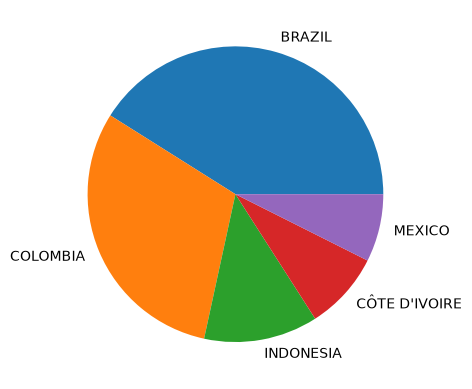

In [169]:
# pie chart for emphasis
nineties_totals.plot(kind="pie", x="Country", y="Total")

### 1.4 Stakeholder Summary

In the early 90s, Brazil dominated the coffee world, exporting over 5.5 billion units. A close runner up was Columbia, with 4.1 billion units. Indonesia, Ivory Coast, and Mexico made the top 5, but lag behind significantly, with export numbers hovering around 1-1.5 mil.

### 1.5 Data Limitations

Some of our records are missing for countries in the early 90s. For our purposes, only one case of a single missing value was found for Congo, and other missing values point toward missing data keeping (only having one year recorded--perhaps these countries were just entering the scene). So, we have been thorough with the data at hand, however it may be useful to follow up on Guyana, Liberia, Nepal, and Timor-Leste.

## 2. Top Five Coffee Producers (1999–2004)

Scenario: The sourcing department wants to diversify global suppliers while targeting regions with robust, stable production capacities.

### 2.1 Analysis Code

In [170]:
# we want column range 1999-2004, and each set of row values totalled, and associated with their label
millenial_prod = coffee_prod.loc[:,1999:2004]
millenial_prod

,1999,2000,2001,2002,2003,2004
Country,,,,,,
ANGOLA,"3,300,000","3,000,000","1,260,000","3,420,000","2,280,000","900,000"
BOLIVIA (PLURINATIONAL STATE OF),"9,480,000","8,880,000","5,640,000","7,620,000","6,180,000","9,300,000"
BRAZIL,"2,854,680,000","1,878,600,000","1,881,900,000","2,901,120,000","1,732,380,000","2,356,860,000"
BURUNDI,"21,060,000","29,220,000","8,640,000","27,240,000","20,280,000","26,220,000"
CAMEROON,"82,200,000","66,780,000","41,160,000","48,060,000","54,000,000","43,620,000"
CENTRAL AFRICAN REPUBLIC,"14,460,000","6,780,000","4,080,000","5,520,000","2,580,000","1,740,000"
COLOMBIA,"570,720,000","631,140,000","717,000,000","702,720,000","663,180,000","685,740,000"
CONGO,"180,000","180,000","180,000","180,000","180,000","180,000"
COSTA RICA,"149,100,000","145,140,000","134,820,000","122,580,000","113,160,000","112,560,000"


In [171]:

millenial_prod_totals = millenial_prod.sum(axis=1)
millenial_prod_totals = totals.nlargest(5)
millenial_prod_totals

Country
BRAZIL          5,521,260,000
COLOMBIA        4,106,580,000
INDONESIA       1,676,700,000
CÔTE D'IVOIRE   1,146,660,000
MEXICO            995,940,000
dtype: float64

### 2.2 Output Table

In [172]:
# convert Series to DataFrame
millenial_prod_totals.to_frame(name="Totals")

,Totals
Country,
BRAZIL,"5,521,260,000"
COLOMBIA,"4,106,580,000"
INDONESIA,"1,676,700,000"
CÔTE D'IVOIRE,"1,146,660,000"
MEXICO,"995,940,000"


### 2.3 Visualization

<Axes: >

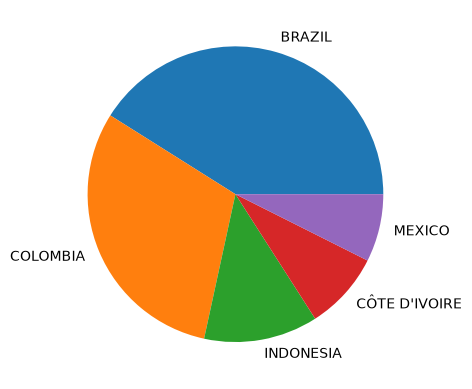

In [173]:
# pie chart for emphasis
millenial_prod_totals.plot(kind="pie", x="Country", y="Total")

### 2.4 Stakeholder Summary

While Brazil dominates the world of coffee production, Viet Nam is on the rise, having overtaken Columbia in the past decade (note that this is based on previous analysis from the early 90s). If looking to diversify, entrepreneurs might consider Viet Nam for future investment. Since previous study indicates other producers dominated the market in the early 90s, with Colubmia being a stable runner-up, it is important to consider both Brazil (the MVP) the primary producer, and then Columbia a stabel runner-up, while Viet Nam proves to be a new and exciting option (not to be ignored!). We might consider strengthening our business ties with Viet Nam producers since this is the #2 producer globally.


### 2.5 Data Limitations

The data is missing values for Nepal and Equatorial Guinea

## 3. High-Potential "Hidden Gem" Producers

Scenario: Rather than focusing exclusively on top-tier market leaders, executives want to identify strong secondary suppliers that could serve as future strategic partners.

### 3.1 Analysis Code

In [174]:
# make a new df of just columns 0-6
early90sProd = coffee_prod.iloc[:,0:6] # select relevant columns
# print new df
# early90sProd 
early90sProd.groupby(coffee_prod['Coffee type']).sum() # type totals irrespective of Country --prints totals each year



,1990,1991,1992,1993,1994
Coffee type,,,,,
Arabica,"1,807,140,000","2,073,960,000","1,895,580,000","1,593,720,000","1,715,940,000"
Arabica/Robusta,"2,399,820,000","2,409,960,000","2,787,060,000","2,492,700,000","2,503,560,000"
Robusta,"266,400,000","354,840,000","228,840,000","198,840,000","269,700,000"
Robusta/Arabica,"1,120,440,000","1,237,380,000","999,780,000","1,220,280,000","1,109,640,000"


In [175]:
# check for category type anomolies
early90sProd['Coffee type'].value_counts().sum()

# check that no labels were dropped --> output is 55
# early90sProd['Coffee type'].value_counts().sum() 

np.int64(55)

In [176]:
ctype_totals = early90sProd.iloc[:, 1:6].sum(axis=1)
ctype_totals
early90sProd['rank'] = early90sProd.groupby('Coffee type')['total'].rank(ascending=False)
# early90sProd[early90sProd.duplicated(['Coffee type', 'total'], keep=False)] # check for duplicates

KeyError: 'Column not found: total'

In [ ]:
early90sProd['total'] = ctype_totals
early90sProd
# print cumulative total of each type for the period:
# early90sProd.groupby('Coffee type')['total'].sum()

,Coffee type,1990,1991,1992,1993,1994,total,rank
Country,,,,,,,,
ANGOLA,Robusta/Arabica,"3,000,000","4,740,000","4,680,000","1,980,000","4,620,000","19,020,000",10
BOLIVIA (PLURINATIONAL STATE OF),Arabica,"7,380,000","6,240,000","7,200,000","3,060,000","7,020,000","30,900,000",15
BRAZIL,Arabica/Robusta,"1,637,160,000","1,637,580,000","2,076,180,000","1,690,020,000","1,691,520,000","8,732,460,000",1
BURUNDI,Arabica/Robusta,"29,220,000","40,020,000","37,200,000","23,580,000","39,840,000","169,860,000",8
CAMEROON,Robusta/Arabica,"100,920,000","103,560,000","15,600,000","40,980,000","24,360,000","285,420,000",7
CENTRAL AFRICAN REPUBLIC,Robusta,"10,500,000","7,500,000","8,040,000","9,960,000","15,000,000","51,000,000",4
COLOMBIA,Arabica,"863,760,000","1,078,800,000","896,820,000","685,320,000","777,840,000","4,302,540,000",1
CONGO,Robusta,"180,000","180,000","180,000","180,000","480,000","1,200,000",10
COSTA RICA,Arabica,"153,720,000","165,600,000","179,880,000","141,540,000","148,920,000","789,660,000",3


In [ ]:
# index comes along automatically when selecting columns, so choose columns and sort:
cols = ['Coffee type', 'total', 'rank']
# sort_values is like lastname, firstname (phonebook lookup)
rankings = early90sProd[cols].sort_values(['Coffee type', 'rank'])
rankings

,Coffee type,total,rank
Country,,,
COLOMBIA,Arabica,"4,302,540,000",1
ETHIOPIA,Arabica,"803,340,000",2
COSTA RICA,Arabica,"789,660,000",3
EL SALVADOR,Arabica,"740,100,000",4
HONDURAS,Arabica,"589,080,000",5
KENYA,Arabica,"438,360,000",6
PERU,Arabica,"344,580,000",7
VENEZUELA,Arabica,"336,000,000",8
NICARAGUA,Arabica,"186,240,000",9


In [ ]:
rankings.groupby('Coffee type').head(5)

,Coffee type,total,rank
Country,,,
COLOMBIA,Arabica,"4,302,540,000",1
ETHIOPIA,Arabica,"803,340,000",2
COSTA RICA,Arabica,"789,660,000",3
EL SALVADOR,Arabica,"740,100,000",4
HONDURAS,Arabica,"589,080,000",5
BRAZIL,Arabica/Robusta,"8,732,460,000",1
MEXICO,Arabica/Robusta,"1,319,040,000",2
GUATEMALA,Arabica/Robusta,"1,104,540,000",3
ECUADOR,Arabica/Robusta,"555,480,000",4


### 3.2 Output Table

In [ ]:
top3 = rankings.groupby('Coffee type').head(3)
top3

,Coffee type,total,rank
Country,,,
COLOMBIA,Arabica,"4,302,540,000",1
ETHIOPIA,Arabica,"803,340,000",2
COSTA RICA,Arabica,"789,660,000",3
BRAZIL,Arabica/Robusta,"8,732,460,000",1
MEXICO,Arabica/Robusta,"1,319,040,000",2
GUATEMALA,Arabica/Robusta,"1,104,540,000",3
CÔTE D'IVOIRE,Robusta,"876,840,000",1
MADAGASCAR,Robusta,"247,200,000",2
TOGO,Robusta,"63,060,000",3


### 3.3 Visualization

[Text(0, 0, 'COLOMBIA'),
 Text(0, 0, 'ETHIOPIA'),
 Text(0, 0, 'COSTA RICA'),
 Text(0, 0, 'BRAZIL'),
 Text(0, 0, 'MEXICO'),
 Text(0, 0, 'GUATEMALA'),
 Text(0, 0, "CÔTE D'IVOIRE"),
 Text(0, 0, 'MADAGASCAR'),
 Text(0, 0, 'TOGO'),
 Text(0, 0, 'INDONESIA'),
 Text(0, 0, 'INDIA'),
 Text(0, 0, 'UGANDA')]

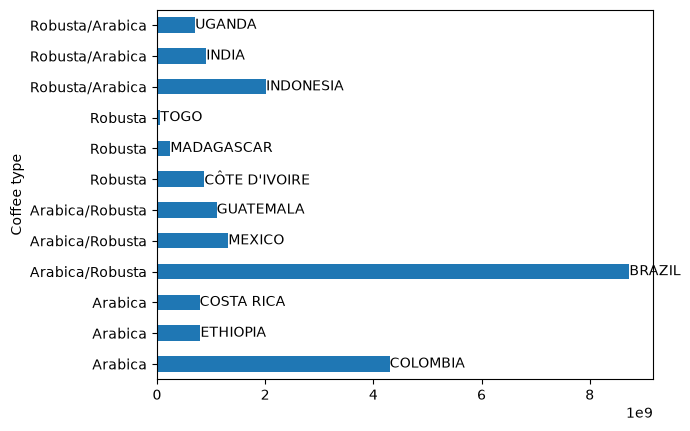

In [ ]:
# one chart per group, index is the label, y is the number
# top3.plot.barh(x='Coffee type', y='total')
ax = top3.plot.barh(x='Coffee type', y='total', legend=False)
ax.bar_label(ax.containers[0], labels=top3.index, label_type='edge')
# for coffee_type, rows in top3.groupby('Coffee type'):
#     rows.plot.barh(y='total', title=coffee_type)

### 3.4 Stakeholder Summary

What we discovered:
For countries with a single coffee-type export, Ivory Coast is a strong contender for the "Robusta" coffeetype. It is by no means one of the leading coffee producers overall, however it leads in this speciality and may provide an avenue for a focused sales product. A niche followup could be done with Madagascar as well. Columbia dominates for single export of Arabica type. Second in this category are, neck-in-neck, Costa Rica and Ethiopia. For a product line that focuses on single-origin and focused type, there may be interesting market opportunities here. It is worth mentioning that there are coffee producers with multiple types produced that greatly exceed these single-origin country focuses and may be worth a followup for examination.

### 3.5 Data Limitations

Exact matching preserves coffee type categories "Robusta/Arabica" and "Arabica/Robusta". Since there is not enough information to determine percentages of each coffee type or potential blends, these were treated as distinct categories in case reference was wanted. It would be worth following-up with the owner of the csv file for the thought process behind this. In some cases the combined categories had significantly higher production output than single coffee types. FOr instance, Indonesia's production is over 2 billion, eclipsing the leading "Robusta" producer Ivory Coast with its 875 mil.

## 4. Global Coffee Trade Footprints

Scenario: The company needs to map out market liquidity and identify the primary nations moving the global trade needle, whether via importing or exporting.

### 4.1 Analysis Code

In [ ]:
# combine total exports and imports
exp_totals = coffee_exp.sum(axis=1)
exp_totals
imp_totals = coffee_imp.sum(axis=1)
imp_totals

Country
AUSTRIA                     5,531,520,000
BELGIUM                    12,481,080,000
BELGIUM/LUXEMBOURG          2,515,800,000
BULGARIA                    1,661,400,000
CROATIA                     1,244,160,000
CYPRUS                        260,760,000
CZECHIA                     3,632,040,000
DENMARK                     3,483,720,000
ESTONIA                       537,960,000
FINLAND                     4,303,680,000
FRANCE                     23,945,040,000
GERMANY                    62,962,800,000
GREECE                      3,280,080,000
HUNGARY                     2,654,880,000
IRELAND                       768,600,000
ITALY                      26,544,240,000
LATVIA                        523,080,000
LITHUANIA                     946,920,000
LUXEMBOURG                    831,240,000
MALTA                          59,400,000
NETHERLANDS                11,902,800,000
POLAND                      9,631,080,000
PORTUGAL                    3,137,400,000
ROMANIA                   

In [ ]:
vol = exp_totals.add(imp_totals, fill_value=0)

### 4.2 Output Table

In [ ]:
top5 = vol.nlargest(5)
top5.to_frame(name="total volume")

,total volume
Country,
UNITED STATES OF AMERICA,"85,015,320,000"
BRAZIL,"67,615,418,112"
GERMANY,"62,962,800,000"
VIET NAM,"49,848,960,000"
COLOMBIA,"39,756,960,000"


### 4.3 Visualization

<Axes: ylabel='Country'>

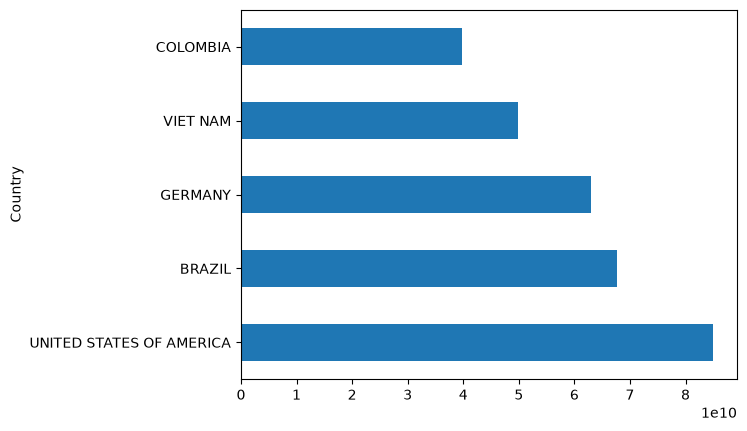

In [ ]:
top5.plot(kind='barh')

### 4.4 Stakeholder Summary

The USA takes first place in the global market, coming out on top is the worlds' most coffee-loving country. This is followed by Brazil, then Germany. For total volume moved, first and third place go to importers (USA, Germany), and then second, fourth, and 5th to the strongest exporters. It is necessarily the case the the USA must import from multiple countries, and likewise Germany must also import from multiple countries, since no single exporter can match the existing import volume. USA's requirement for such high volume import implies a trade reliance on the strongest exporters, and may also view Germany as a competitor for coffee acquisition. For exporters, there may be value in recognizing that these two strong importers could be pressured to pay more should there be coffee shortages in the future.

### 4.5 Data Limitations

We do have some missing values for some countries.

## 5. Sourcing Traceability Analysis

Scenario: The Vice President of Supply Chain wants a precise mapping of the global supply network—specifically tracking exactly which exporting countries supplied each individual importing country.

While this objective is compelling and could lead to valuable insights, the current data is not sufficient to manipulate for this analysis. Each csv file represents a single direction: which countries exported coffee, how much, and when? This is the same pattern for imports and production. It is not possible to make reasonable connections between countries based on the data. We can draw broader conclusions, such as, the USA must have imported from multiple countries due to its total volume being greater than any exporter, however that hardly helps in identifying and clarifying specifics of the global supply network.

In order to better address this question, we would need bilateral data, so, records that name two countries in relation to each other. If a country exported coffee, where did it export this coffee? Such questions cannot be answered with these data sets.